# HW3 — Final Naive Bayes Submission

**Santander Customer Transaction Prediction.** Final model: **BernoulliNB on 20-bin quantile-discretized features**. This configuration was identified as the winner in [`03_nb_experiments.ipynb`](03_nb_experiments.ipynb) — local CV 0.89046, comfortably above the 0.89 target.

Pipeline:
1. Load data
2. Discretize each feature into 20 quantile bins (per CV fold, fit on train only)
3. Stratified 5-fold CV with BernoulliNB
4. Refit on full train + predict on test
5. Write submission file

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.naive_bayes import BernoulliNB
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve

import warnings
warnings.filterwarnings('ignore')

DATA_DIR = 'data'
RANDOM_STATE = 42
N_BINS = 20
sns.set_style('whitegrid')

## 1. Load Data

In [2]:
feature_cols = [f'var_{i}' for i in range(200)]
train_dtypes = {c: np.float32 for c in feature_cols} | {'target': np.int8}
test_dtypes = {c: np.float32 for c in feature_cols}

df_train = pd.read_csv(f'{DATA_DIR}/train.csv', dtype=train_dtypes)
df_test = pd.read_csv(f'{DATA_DIR}/test.csv', dtype=test_dtypes)

X = df_train[feature_cols].values
y = df_train['target'].values
X_test = df_test[feature_cols].values
test_ids = df_test['ID_code'].values

print(f'Train: {df_train.shape}  Test: {df_test.shape}')
print(f'Positive class: {y.mean() * 100:.2f}%')

Train: (200000, 202)  Test: (200000, 201)
Positive class: 10.05%


## 2. Stratified 5-Fold Cross-Validation

Each fold: fit `KBinsDiscretizer(n_bins=20, strategy='quantile')` on the training slice only, transform train + validation, train BernoulliNB, score AUC on validation.

In [3]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
fold_aucs = []
oof = np.zeros(len(y))

for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y), 1):
    disc = KBinsDiscretizer(n_bins=N_BINS, encode='onehot', strategy='quantile')
    disc.fit(X[tr_idx])
    X_tr = disc.transform(X[tr_idx])
    X_va = disc.transform(X[va_idx])

    model = BernoulliNB()
    model.fit(X_tr, y[tr_idx])
    p = model.predict_proba(X_va)[:, 1]
    oof[va_idx] = p
    auc = roc_auc_score(y[va_idx], p)
    fold_aucs.append(auc)
    print(f'  Fold {fold}: AUC = {auc:.5f}')

fold_aucs = np.array(fold_aucs)
print(f'\nMean AUC: {fold_aucs.mean():.5f}  |  Std: {fold_aucs.std():.5f}')

  Fold 1: AUC = 0.89255
  Fold 2: AUC = 0.89071
  Fold 3: AUC = 0.88588
  Fold 4: AUC = 0.89206
  Fold 5: AUC = 0.89109

Mean AUC: 0.89046  |  Std: 0.00238


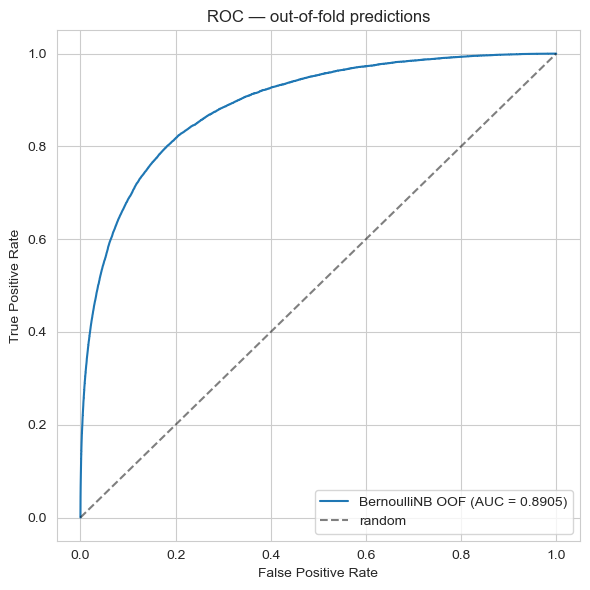

In [4]:
# ROC curve from out-of-fold predictions
fpr, tpr, _ = roc_curve(y, oof)
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(fpr, tpr, label=f'BernoulliNB OOF (AUC = {fold_aucs.mean():.4f})')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='random')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC — out-of-fold predictions')
ax.legend()
plt.tight_layout()
plt.show()

## 3. Final Fit on Full Train + Test Prediction

Refit the discretizer and BernoulliNB on the complete training set, then predict on the test set.

In [5]:
final_disc = KBinsDiscretizer(n_bins=N_BINS, encode='onehot', strategy='quantile')
final_disc.fit(X)
X_train_disc = final_disc.transform(X)
X_test_disc = final_disc.transform(X_test)

final_model = BernoulliNB()
final_model.fit(X_train_disc, y)
test_proba = final_model.predict_proba(X_test_disc)[:, 1]

print(f'Predicted {len(test_proba):,} test rows')
print(f'  mean prob: {test_proba.mean():.4f}  (target base rate: {y.mean():.4f})')
print(f'  std prob:  {test_proba.std():.4f}')
print(f'  range:     [{test_proba.min():.4f}, {test_proba.max():.4f}]')

Predicted 200,000 test rows
  mean prob: 0.0923  (target base rate: 0.1005)
  std prob:  0.1677
  range:     [0.0000, 0.9996]


## 4. Submission File

In [6]:
submission = pd.DataFrame({'ID_code': test_ids, 'target': test_proba})
submission.to_csv('submission_naive_bayes_final.csv', index=False)
print(f'Wrote submission_naive_bayes_final.csv  ({len(submission):,} rows)')
submission.head()

Wrote submission_naive_bayes_final.csv  (200,000 rows)


,ID_code,target
0,test_0,0.275398
1,test_1,0.294391
2,test_2,0.202597
3,test_3,0.153502
4,test_4,0.024111


## 5. Kaggle Submission

Submit `submission_naive_bayes_final.csv` at:

https://www.kaggle.com/competitions/santander-customer-transaction-prediction/submit

Capture a screenshot of your public-leaderboard position for the deliverables.